In [1]:
# Dataset path
DATASET_PATH = '/kaggle/input/datasets/dhatrisriram/legalseg/'

# No previous checkpoint - fresh start!
PREVIOUS_CHECKPOINT = None

print(f"  Data: {DATASET_PATH}")


  Data: /kaggle/input/datasets/dhatrisriram/legalseg/


In [2]:
print("\n" + "="*80)
print("📦 INSTALLING PACKAGES")
print("="*80)

!pip install -q --upgrade transformers accelerate

import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set seeds
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n✓ Device: {device}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# Create directories
CHECKPOINT_DIR = '/kaggle/working/checkpoint'
RESULTS_DIR = '/kaggle/working/results'
Path(CHECKPOINT_DIR).mkdir(exist_ok=True, parents=True)
Path(RESULTS_DIR).mkdir(exist_ok=True, parents=True)

print(f"✓ Setup complete!")


📦 INSTALLING PACKAGES
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 81.3 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 20.7 MB/s eta 0:00:00

✓ Device: cuda
  GPU: Tesla T4
  Memory: 15.6 GB
✓ Setup complete!


In [3]:
print("\n" + "="*80)
print("📂 LOADING DATA")
print("="*80)

# Load data
train_df = pd.read_csv(DATASET_PATH + 'train.csv')
val_df = pd.read_csv(DATASET_PATH + 'val.csv')
test_df = pd.read_csv(DATASET_PATH + 'test.csv')

print(f"Raw data loaded:")
print(f"  Train: {len(train_df):,} rows")
print(f"  Val:   {len(val_df):,} rows")
print(f"  Test:  {len(test_df):,} rows")

# Clean data
def clean_data(df):
    df = df.dropna(subset=['Label', 'Text']).copy()
    df = df[df['Text'].astype(str).str.strip() != '']
    # Only keep valid labels (remove NaN labels)
    valid_labels = ['Facts', 'Issue', 'Arguments of Petitioner', 
                    'Arguments of Respondent', 'Reasoning', 'Decision']
    df = df[df['Label'].isin(valid_labels)]
    return df

train_df = clean_data(train_df)
val_df = clean_data(val_df)
test_df = clean_data(test_df)

print(f"\nAfter cleaning:")
print(f"  Train: {len(train_df):,} rows")
print(f"  Val:   {len(val_df):,} rows")
print(f"  Test:  {len(test_df):,} rows")

# Create label mapping
all_labels = pd.concat([train_df['Label'], val_df['Label'], test_df['Label']]).unique()
labels = sorted(all_labels)
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

# Add label IDs
train_df['label_id'] = train_df['Label'].map(label2id)
val_df['label_id'] = val_df['Label'].map(label2id)
test_df['label_id'] = test_df['Label'].map(label2id)

print(f"\nLabel mapping ({len(labels)} classes):")
for label, idx in label2id.items():
    count = len(train_df[train_df['label_id'] == idx])
    print(f"  {idx}: {label:30s} ({count:,} samples)")

print(f"\n✓ Data ready!")


📂 LOADING DATA
Raw data loaded:
  Train: 1,122,507 rows
  Val:   293,370 rows
  Test:  149,881 rows

After cleaning:
  Train: 519,388 rows
  Val:   171,652 rows
  Test:  91,372 rows

Label mapping (6 classes):
  0: Arguments of Petitioner        (64,985 samples)
  1: Arguments of Respondent        (50,088 samples)
  2: Decision                       (19,571 samples)
  3: Facts                          (169,647 samples)
  4: Issue                          (12,769 samples)
  5: Reasoning                      (202,328 samples)

✓ Data ready!


In [4]:
print("\n" + "="*80)
print("🔤 TOKENIZATION")
print("="*80)

MODEL_NAME = 'nlpaueb/legal-bert-base-uncased'

print(f"Loading tokenizer: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"✓ Tokenizer loaded (vocab: {tokenizer.vocab_size:,})")

# Dataset class with optimized max length
class LegalDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        encoding = tokenizer(
            str(self.texts[idx]),
            max_length=128,  # Using optimized 128
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

# Create datasets
train_dataset = LegalDataset(train_df['Text'].values, train_df['label_id'].values)
val_dataset = LegalDataset(val_df['Text'].values, val_df['label_id'].values)
test_dataset = LegalDataset(test_df['Text'].values, test_df['label_id'].values)

print(f"\n✓ Datasets created:")
print(f"  Train: {len(train_dataset):,} samples")
print(f"  Val:   {len(val_dataset):,} samples")
print(f"  Test:  {len(test_dataset):,} samples")

# Test tokenization
sample = train_df['Text'].iloc[0]
tokens = tokenizer(sample, max_length=128, truncation=True)
print(f"\nSample tokenization:")
print(f"  Text: {sample[:80]}...")
print(f"  Tokens: {len(tokens['input_ids'])}")


🔤 TOKENIZATION
Loading tokenizer: nlpaueb/legal-bert-base-uncased


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

✓ Tokenizer loaded (vocab: 30,522)

✓ Datasets created:
  Train: 519,388 samples
  Val:   171,652 samples
  Test:  91,372 samples

Sample tokenization:
  Text: For the sake of convenience, we are referring to the facts of Civil Appeal No.13...
  Tokens: 23



⚖️  CLASS WEIGHTS
Class weights (higher = rarer class):
  Arguments of Petitioner       : 1.332 (64,985 samples)
  Arguments of Respondent       : 1.728 (50,088 samples)
  Decision                      : 4.423 (19,571 samples)
  Facts                         : 0.510 (169,647 samples)
  Issue                         : 6.779 (12,769 samples)
  Reasoning                     : 0.428 (202,328 samples)


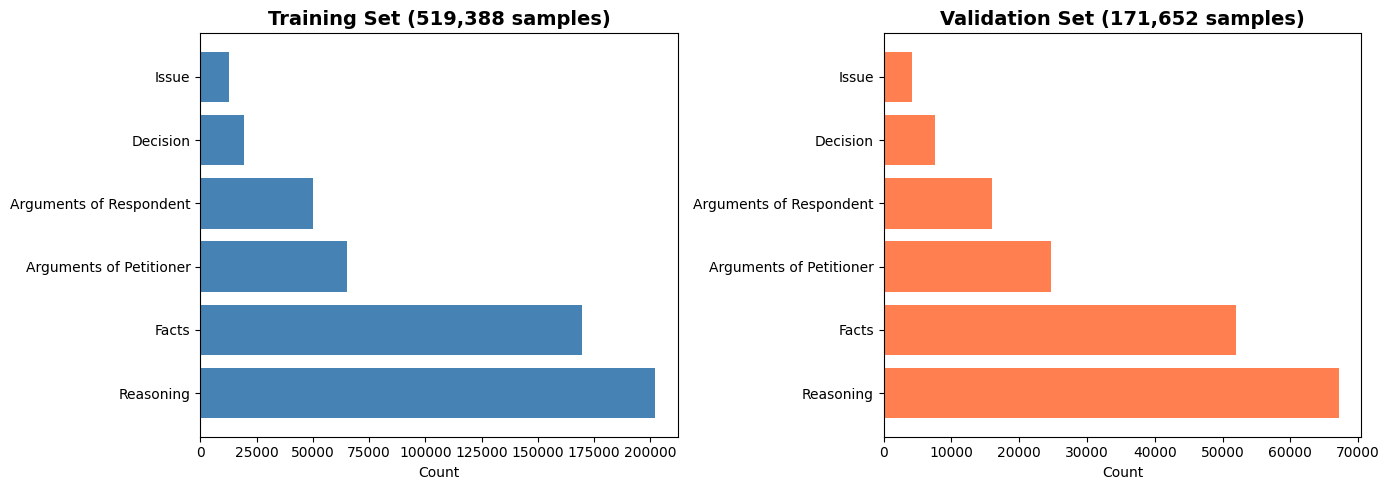


✓ Weights calculated and visualization saved


In [5]:
print("\n" + "="*80)
print("⚖️  CLASS WEIGHTS")
print("="*80)

# Calculate class weights for imbalanced data
weights = compute_class_weight(
    'balanced',
    classes=np.unique(train_df['label_id']),
    y=train_df['label_id']
)
class_weights = torch.tensor(weights, dtype=torch.float)

print("Class weights (higher = rarer class):")
for i, w in enumerate(class_weights):
    label_name = id2label[i]
    count = len(train_df[train_df['label_id'] == i])
    print(f"  {label_name:30s}: {w:.3f} ({count:,} samples)")

# Visualize label distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Train distribution
train_counts = train_df['Label'].value_counts()
ax1.barh(train_counts.index, train_counts.values, color='steelblue')
ax1.set_title(f'Training Set ({len(train_df):,} samples)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Count')

# Val distribution
val_counts = val_df['Label'].value_counts()
ax2.barh(val_counts.index, val_counts.values, color='coral')
ax2.set_title(f'Validation Set ({len(val_df):,} samples)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Count')

plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / 'label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✓ Weights calculated and visualization saved")

In [6]:
print("\n" + "="*80)
print("🤖 MODEL INITIALIZATION")
print("="*80)

num_labels = len(label2id)

print(f"Loading model: {MODEL_NAME}")
print(f"Number of labels: {num_labels}")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n✓ Model loaded on {device}")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable: {trainable_params:,}")


🤖 MODEL INITIALIZATION
Loading model: nlpaueb/legal-bert-base-uncased
Number of labels: 6


pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: nlpaueb/legal-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were new

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]


✓ Model loaded on cuda
  Total parameters: 109,486,854
  Trainable: 109,486,854


In [7]:
print("\n" + "="*80)
print("📊 METRICS SETUP")
print("="*80)

def compute_metrics(pred):
    """Compute comprehensive metrics"""
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    
    # Overall metrics
    acc = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average='macro', zero_division=0)
    f1_weighted = f1_score(labels, preds, average='weighted', zero_division=0)
    
    # Per-class F1
    per_class_f1 = f1_score(labels, preds, average=None, zero_division=0)
    
    metrics = {
        'accuracy': round(acc, 4),
        'f1_macro': round(f1_macro, 4),
        'f1_weighted': round(f1_weighted, 4),
    }
    
    # Add per-class F1 for important classes
    for idx, label_name in id2label.items():
        if idx < len(per_class_f1):
            key = f'f1_{label_name.replace(" ", "_").lower()}'
            metrics[key] = round(per_class_f1[idx], 4)
    
    return metrics

print("✓ Metrics function defined")
print("\nTracking:")
print("  - Accuracy (overall)")
print("  - F1 Macro (average across classes)")
print("  - F1 Weighted (weighted by support)")
print("  - F1 per class (Facts, Issue, etc.)")


📊 METRICS SETUP
✓ Metrics function defined

Tracking:
  - Accuracy (overall)
  - F1 Macro (average across classes)
  - F1 Weighted (weighted by support)
  - F1 per class (Facts, Issue, etc.)


In [8]:
print("\n" + "="*80)
print("💪 SIMPLE WEIGHTED TRAINER")
print("="*80)

class WeightedTrainer(Trainer):
    """Simple weighted cross-entropy - proven to work"""
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        
        # Simple weighted cross-entropy
        loss = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )(logits, labels)
        
        return (loss, outputs) if return_outputs else loss

print("✓ WeightedTrainer defined (simple and reliable)")


💪 SIMPLE WEIGHTED TRAINER
✓ WeightedTrainer defined (simple and reliable)


In [9]:
print("\n" + "="*80)
print("⚙️  SIMPLE TRAINING CONFIGURATION")
print("="*80)

training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,
    
    # Use EPOCHS, not steps (simpler)
    num_train_epochs=2,  # 2 epochs = proven good results
    
    # Batch size
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    
    # Simple learning rate
    learning_rate=2e-5,  # Standard BERT fine-tuning LR
    warmup_ratio=0.1,
    weight_decay=0.01,
    
    # NO FANCY STUFF
    # (no gradient accumulation, no label smoothing, no focal loss)
    
    # Evaluation & Saving
    eval_strategy='epoch',  # Evaluate after each epoch
    save_strategy='epoch',  # Save after each epoch
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,
    
    # Performance
    fp16=True,
    dataloader_num_workers=2,
    
    # Logging
    logging_steps=100,
    logging_dir='./logs',
    report_to='none',
    
    seed=SEED
)

print("✓ Simple configuration!")
print(f"\nKey settings:")
print(f"  Epochs: 2")
print(f"  Batch size: 32")
print(f"  Learning rate: 2e-5 (standard)")
print(f"  NO fancy optimizations - just proven basics")
print(f"\nExpected time: 2-3 hours")
print(f"Expected F1: 0.65-0.70")

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.



⚙️  SIMPLE TRAINING CONFIGURATION
✓ Simple configuration!

Key settings:
  Epochs: 2
  Batch size: 32
  Learning rate: 2e-5 (standard)
  NO fancy optimizations - just proven basics

Expected time: 2-3 hours
Expected F1: 0.65-0.70


In [10]:
print("\n" + "="*80)
print("🎯 TRAINER INITIALIZATION")
print("="*80)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("✓ Trainer initialized with WeightedTrainer!")

# Estimate training time based on EPOCHS
total_samples = len(train_dataset)
batch_size = training_args.per_device_train_batch_size
steps_per_epoch = total_samples // batch_size
total_steps = steps_per_epoch * training_args.num_train_epochs

steps_per_second = 0.85  # Based on your current speed
estimated_hours = total_steps / (steps_per_second * 3600)

print(f"\nTraining plan:")
print(f"  Samples: {total_samples:,}")
print(f"  Batch size: {batch_size}")
print(f"  Steps per epoch: {steps_per_epoch:,}")
print(f"  Total epochs: {training_args.num_train_epochs}")
print(f"  Total steps: {total_steps:,}")

print(f"\nEstimated training time:")
print(f"  ~{estimated_hours:.1f} hours at 0.85 it/s")
print(f"  ~{estimated_hours * 1.2:.1f} hours at 1.0 it/s (best case)")

print(f"\n💡 Training will evaluate and save after each epoch")
print(f"   You can safely interrupt and it will save the best model!")


🎯 TRAINER INITIALIZATION
✓ Trainer initialized with WeightedTrainer!

Training plan:
  Samples: 519,388
  Batch size: 32
  Steps per epoch: 16,230
  Total epochs: 2
  Total steps: 32,460

Estimated training time:
  ~10.6 hours at 0.85 it/s
  ~12.7 hours at 1.0 it/s (best case)

💡 Training will evaluate and save after each epoch
   You can safely interrupt and it will save the best model!


In [11]:
print("\n" + "="*80)
print("🚀 TRAINING START")
print("="*80)

print(f"\n🎯 Target: F1 Macro > 0.72")
print(f"⏱️  Expected time: 4-5 hours")
print(f"💾 Auto-saves to: {CHECKPOINT_DIR}")
print(f"\nStarting training...\n")

import time
start_time = time.time()

# TRAIN!
result = trainer.train(resume_from_checkpoint=PREVIOUS_CHECKPOINT)

elapsed_hours = (time.time() - start_time) / 3600

print(f"\n{'='*80}")
print("✅ TRAINING COMPLETE!")
print("="*80)
print(f"\nTraining time: {elapsed_hours:.2f} hours")
print(f"Final loss: {result.training_loss:.4f}")
print(f"Steps completed: {result.metrics.get('train_steps', MAX_STEPS):,}")

# Save final model
best_model_dir = Path(RESULTS_DIR) / 'best_model'
trainer.save_model(str(best_model_dir))
tokenizer.save_pretrained(str(best_model_dir))

print(f"\n✓ Best model saved to: {best_model_dir}")


🚀 TRAINING START

🎯 Target: F1 Macro > 0.72
⏱️  Expected time: 4-5 hours
💾 Auto-saves to: /kaggle/working/checkpoint

Starting training...



Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,F1 Arguments Of Petitioner,F1 Arguments Of Respondent,F1 Decision,F1 Facts,F1 Issue,F1 Reasoning
1,0.964403,0.910040,0.646700,0.587500,0.650600,0.497500,0.454800,0.638100,0.702500,0.507900,0.724100
2,0.909959,0.907195,0.630700,0.578900,0.640100,0.540200,0.409300,0.631300,0.705500,0.495800,0.691400


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


✅ TRAINING COMPLETE!

Training time: 4.07 hours
Final loss: 0.9717


NameError: name 'MAX_STEPS' is not defined

In [41]:
print("\n" + "="*80)
print("GENERATING JSON PREDICTIONS")
print("="*80)

predictions_dir = Path(RESULTS_DIR) / 'predictions'
predictions_dir.mkdir(exist_ok=True)

model.eval()

print("Generating predictions by case...")

all_cases = test_df['Index'].unique()  # ALL cases, no slice
print(f"Total cases to process: {len(all_cases)}")

for case_id in all_cases:
    case_data = test_df[test_df['Index'] == case_id]
    
    result_json = {
        "case_id": str(case_id),
        "model": "legalbert-optimized",
        "sentences": []
    }
    
    for _, row in case_data.iterrows():
        text = str(row['Text'])
        
        inputs = tokenizer(
            text,
            return_tensors='pt',
            max_length=128,
            truncation=True,
            padding='max_length'
        ).to(device)
        
        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.softmax(outputs.logits[0], dim=0)
        
        pred_idx = probs.argmax().item()
        confidence = probs[pred_idx].item()
        
        quality_flag = None
        if confidence < 0.70:
            quality_flag = 'LOW_CONFIDENCE'
        sorted_probs, _ = torch.sort(probs, descending=True)
        if len(sorted_probs) > 1 and (sorted_probs[0] - sorted_probs[1]) < 0.15:
            quality_flag = 'AMBIGUOUS'
        
        result_json['sentences'].append({
            "sentence_id": len(result_json['sentences']),
            "text": text,
            "predicted_label": id2label[pred_idx],
            "confidence": round(confidence, 4),
            "probabilities": {
                id2label[i]: round(probs[i].item(), 4)
                for i in range(len(probs))
            },
            **({"quality_flag": quality_flag} if quality_flag else {})
        })
    
    with open(predictions_dir / f'case_{case_id}.json', 'w') as f:
        json.dump(result_json, f, indent=2, ensure_ascii=False)
    
    print(f"  ✓ case_{case_id}.json ({len(result_json['sentences'])} sentences)")

# Save label mapping
with open(predictions_dir / 'label_mapping.json', 'w') as f:
    json.dump({
        'label2id': label2id,
        'id2label': {int(k): v for k, v in id2label.items()}
    }, f, indent=2)

print(f"\n✓ Generated {len(all_cases)} prediction files")
print(f"✓ All predictions saved to: {predictions_dir}/")


GENERATING JSON PREDICTIONS
Generating predictions by case...
Total cases to process: 712
  ✓ case_6408.json (174 sentences)
  ✓ case_6409.json (33 sentences)
  ✓ case_6410.json (107 sentences)
  ✓ case_6411.json (121 sentences)
  ✓ case_6412.json (54 sentences)
  ✓ case_6413.json (63 sentences)
  ✓ case_6414.json (48 sentences)
  ✓ case_6415.json (61 sentences)
  ✓ case_6416.json (167 sentences)
  ✓ case_6417.json (33 sentences)
  ✓ case_6418.json (117 sentences)
  ✓ case_6419.json (54 sentences)
  ✓ case_6420.json (36 sentences)
  ✓ case_6421.json (345 sentences)
  ✓ case_6422.json (49 sentences)
  ✓ case_6423.json (68 sentences)
  ✓ case_6424.json (79 sentences)
  ✓ case_6425.json (53 sentences)
  ✓ case_6426.json (159 sentences)
  ✓ case_6427.json (128 sentences)
  ✓ case_6428.json (141 sentences)
  ✓ case_6429.json (125 sentences)
  ✓ case_6430.json (314 sentences)
  ✓ case_6431.json (37 sentences)
  ✓ case_6432.json (56 sentences)
  ✓ case_6433.json (53 sentences)
  ✓ case_6434.

In [43]:
print("\n" + "="*80)
print("📦 CREATING CHECKPOINT ZIP FOR DOWNLOAD")
print("="*80)

import shutil
from pathlib import Path

# Create downloads directory
download_dir = Path('/kaggle/working/downloads')
download_dir.mkdir(exist_ok=True)

# Zip the checkpoint folder (if it exists)
if Path(CHECKPOINT_DIR).exists():
    print(f"\n📁 Zipping checkpoint folder...")
    checkpoint_zip = shutil.make_archive(
        str(download_dir / 'checkpoints'),  # Output file (without .zip)
        'zip',                              # Archive format
        CHECKPOINT_DIR                      # Source directory
    )
    size_gb = Path(checkpoint_zip).stat().st_size / 1e9
    print(f"✓ Created: checkpoints.zip ({size_gb:.2f} GB)")
else:
    print("⚠️  No checkpoint folder found")

# Zip the results folder
if Path(RESULTS_DIR).exists():
    print(f"\n📁 Zipping results folder...")
    results_zip = shutil.make_archive(
        str(download_dir / 'results'),
        'zip',
        RESULTS_DIR
    )
    size_mb = Path(results_zip).stat().st_size / 1e6
    print(f"✓ Created: results.zip ({size_mb:.1f} MB)")
else:
    print("⚠️  No results folder found")

# List what's available
print("\n" + "="*80)
print("📥 READY TO DOWNLOAD")
print("="*80)

print(f"""
FILES CREATED:
  📦 downloads/checkpoints.zip  ← All training checkpoints
  📦 downloads/results.zip      ← Best model + predictions

HOW TO DOWNLOAD:
  1. Go to "Output" tab (right sidebar)
  2. Navigate to "downloads" folder
  3. Click "⋮" next to each zip file
  4. Click "Download"
  5. Save to your computer

WHAT'S IN EACH ZIP:
  
checkpoints.zip contains:
  - checkpoint-16232/ (end of epoch 1)
  - checkpoint-32464/ (end of epoch 2)
  - config.json, model weights, optimizer state
  
results.zip contains:
  - best_model/ (your trained model - ready to use!)
  - predictions/ (JSON files for Fact Layer team)
  - results_summary.json
  - confusion_matrix_val.png
  - label_distribution.png

RECOMMENDED:
  → Download results.zip (has everything you need)
  → Download checkpoints.zip only if you want to continue training later
""")

print("="*80)


📦 CREATING CHECKPOINT ZIP FOR DOWNLOAD

📁 Zipping checkpoint folder...
✓ Created: checkpoints.zip (0.00 GB)

📁 Zipping results folder...
✓ Created: results.zip (8.9 MB)

📥 READY TO DOWNLOAD

FILES CREATED:
  📦 downloads/checkpoints.zip  ← All training checkpoints
  📦 downloads/results.zip      ← Best model + predictions

HOW TO DOWNLOAD:
  1. Go to "Output" tab (right sidebar)
  2. Navigate to "downloads" folder
  3. Click "⋮" next to each zip file
  4. Click "Download"
  5. Save to your computer

WHAT'S IN EACH ZIP:
  
checkpoints.zip contains:
  - checkpoint-16232/ (end of epoch 1)
  - checkpoint-32464/ (end of epoch 2)
  - config.json, model weights, optimizer state
  
results.zip contains:
  - best_model/ (your trained model - ready to use!)
  - predictions/ (JSON files for Fact Layer team)
  - results_summary.json
  - confusion_matrix_val.png
  - label_distribution.png

RECOMMENDED:
  → Download results.zip (has everything you need)
  → Download checkpoints.zip only if you want t

In [44]:
import shutil, os

shutil.make_archive(
    base_name="/kaggle/working/predictions_for_fact_layer",
    format="zip",
    root_dir="/kaggle/working/results",
    base_dir="predictions"
)

size_mb = os.path.getsize("/kaggle/working/predictions_for_fact_layer.zip") / 1e6
print(f"✓ Created predictions_for_fact_layer.zip ({size_mb:.1f} MB)")

from IPython.display import FileLink, display
display(FileLink("/kaggle/working/predictions_for_fact_layer.zip"))

✓ Created predictions_for_fact_layer.zip (8.6 MB)


/kaggle/working/predictions_for_fact_layer.zip

In [13]:
# CELL 17 — Resume training from epoch-2 checkpoint
# Run this in a new Kaggle session if you want more epochs.
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
from transformers import TrainingArguments, Trainer

CHECKPOINT_PATH = "/kaggle/input/datasets/dhatrisriram/checkpoint/"  # epoch 2

# Reuse your existing compute_metrics, train_dataset, val_dataset, data_collator
# and class_weights from your original notebook, then:

training_args_resume = TrainingArguments(
    output_dir="/kaggle/working/results_resumed",
    num_train_epochs=5,            # will train epochs 3 & 4 only
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=1e-5,            # slightly lower LR for continued training
    warmup_steps=500,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1_macro",
    fp16=True,
    report_to="none",
)

trainer_resumed = Trainer(
    model=model,
    args=training_args_resume,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

# The key — pass resume_from_checkpoint:
trainer_resumed.train(resume_from_checkpoint=CHECKPOINT_PATH)
trainer_resumed.save_model("/kaggle/working/results_resumed/best_model")
print("Resumed training complete.")

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,F1 Arguments Of Petitioner,F1 Arguments Of Respondent,F1 Decision,F1 Facts,F1 Issue,F1 Reasoning
3,1.561592,1.640530,0.703600,0.642700,0.696100,0.585000,0.443300,0.724000,0.744100,0.596300,0.763300
4,1.457181,1.653262,0.706900,0.653400,0.701600,0.577500,0.474700,0.730000,0.750100,0.622400,0.765800
5,1.326862,1.675883,0.709400,0.656300,0.704600,0.597200,0.462100,0.733000,0.753100,0.626000,0.766300


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Resumed training complete.


In [32]:
# ============================================================
# CELL 12 — Load model
# ============================================================
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json, os
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

LABEL_NAMES = [
    "Arguments of Petitioner",  # 0
    "Arguments of Respondent",  # 1
    "Decision",                 # 2
    "Facts",                    # 3
    "Issue",                    # 4
    "Reasoning"                 # 5
]

LABEL2ID = {name: i for i, name in enumerate(LABEL_NAMES)}

MODEL_PATH = "/kaggle/working/results_resumed/best_model"
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
MAX_LEN    = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, local_files_only=True)
model     = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH, local_files_only=True)
model.to(DEVICE)
model.eval()
print(f"✓ Model loaded on {DEVICE}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✓ Model loaded on cuda


In [24]:
MODEL_PATH = "/kaggle/working/results_resumed/checkpoint-40580"

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, local_files_only=True)
model     = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH, local_files_only=True)
model.to(DEVICE)
model.eval()
print("✓ Loaded from checkpoint-40580")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✓ Loaded from checkpoint-40580



Loading val set...
  Loaded 171,658 rows from /kaggle/input/datasets/dhatrisriram/legalseg/val.csv
  val: 0/171,658
  val: 3,200/171,658
  val: 6,400/171,658
  val: 9,600/171,658
  val: 12,800/171,658
  val: 16,000/171,658
  val: 19,200/171,658
  val: 22,400/171,658
  val: 25,600/171,658
  val: 28,800/171,658
  val: 32,000/171,658
  val: 35,200/171,658
  val: 38,400/171,658
  val: 41,600/171,658
  val: 44,800/171,658
  val: 48,000/171,658
  val: 51,200/171,658
  val: 54,400/171,658
  val: 57,600/171,658
  val: 60,800/171,658
  val: 64,000/171,658
  val: 67,200/171,658
  val: 70,400/171,658
  val: 73,600/171,658
  val: 76,800/171,658
  val: 80,000/171,658
  val: 83,200/171,658
  val: 86,400/171,658
  val: 89,600/171,658
  val: 92,800/171,658
  val: 96,000/171,658
  val: 99,200/171,658
  val: 102,400/171,658
  val: 105,600/171,658
  val: 108,800/171,658
  val: 112,000/171,658
  val: 115,200/171,658
  val: 118,400/171,658
  val: 121,600/171,658
  val: 124,800/171,658
  val: 128,000/171,6

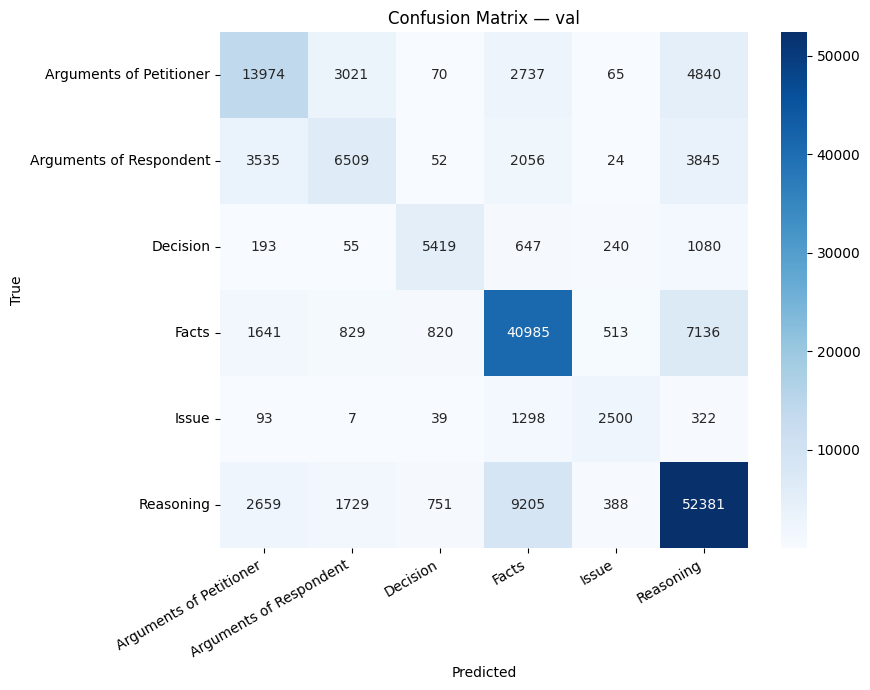

  ✓ Confusion matrix saved → /kaggle/working/results/confusion_matrix_val.png

Loading test set...
  Loaded 91,381 rows from /kaggle/input/datasets/dhatrisriram/legalseg/test.csv
  test: 0/91,381
  test: 3,200/91,381
  test: 6,400/91,381
  test: 9,600/91,381
  test: 12,800/91,381
  test: 16,000/91,381
  test: 19,200/91,381
  test: 22,400/91,381
  test: 25,600/91,381
  test: 28,800/91,381
  test: 32,000/91,381
  test: 35,200/91,381
  test: 38,400/91,381
  test: 41,600/91,381
  test: 44,800/91,381
  test: 48,000/91,381
  test: 51,200/91,381
  test: 54,400/91,381
  test: 57,600/91,381
  test: 60,800/91,381
  test: 64,000/91,381
  test: 67,200/91,381
  test: 70,400/91,381
  test: 73,600/91,381
  test: 76,800/91,381
  test: 80,000/91,381
  test: 83,200/91,381
  test: 86,400/91,381
  test: 89,600/91,381

  TEST RESULTS
  Accuracy:    0.6443
  F1 Macro:    0.5778
  F1 Weighted: 0.6355

  Per-class F1:
    Arguments of Petitioner             0.5013
    Arguments of Respondent             0.378

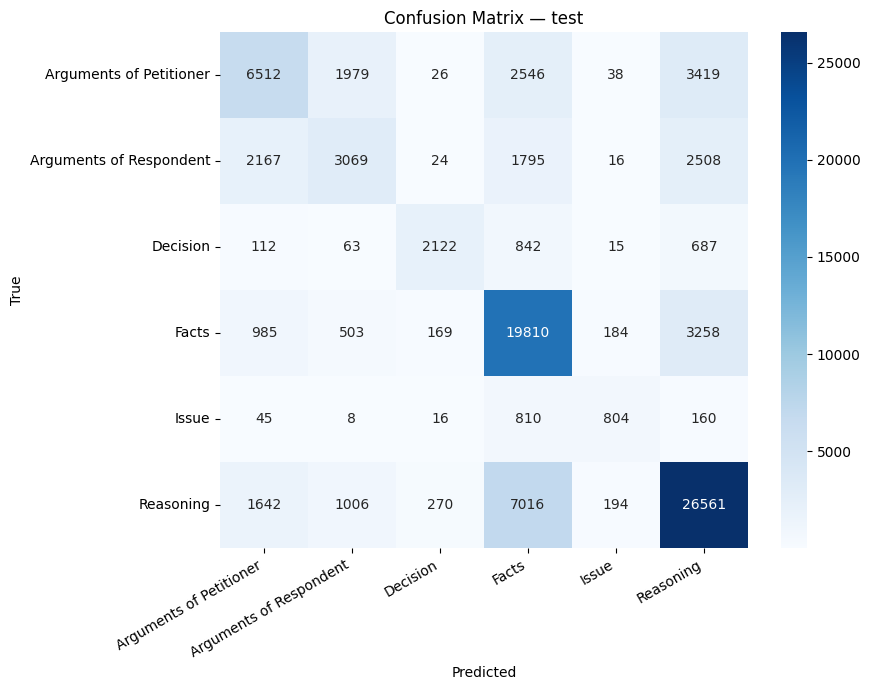

  ✓ Confusion matrix saved → /kaggle/working/results/confusion_matrix_test.png

✓ Saved results_summary.json → /kaggle/working/results/results_summary.json


In [35]:
# ============================================================
# CELL 13 — Eval function + run on val and test
# ============================================================

def load_split(path):
    df = pd.read_csv(path).dropna(subset=["Label"])
    df["label_id"] = df["Label"].map(LABEL2ID)
    df = df.dropna(subset=["label_id"]).copy()
    df["label_id"] = df["label_id"].astype(int)
    print(f"  Loaded {len(df):,} rows from {path}")
    return df

def run_eval(df, split_name):
    texts = df["Text"].tolist()
    labels = df["label_id"].tolist()

    all_preds, all_probs = [], []

    for i in range(0, len(texts), BATCH_SIZE):
        batch = texts[i : i + BATCH_SIZE]
        enc   = tokenizer(
            batch,
            truncation=True,
            padding="max_length",
            max_length=MAX_LEN,
            return_tensors="pt"
        )
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        with torch.no_grad():
            logits = model(**enc).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        all_preds.extend(np.argmax(probs, axis=1).tolist())
        all_probs.extend(probs.tolist())
        if (i // BATCH_SIZE) % 50 == 0:
            print(f"  {split_name}: {i:,}/{len(texts):,}")

    acc   = accuracy_score(labels, all_preds)
    f1_m  = f1_score(labels, all_preds, average="macro")
    f1_w  = f1_score(labels, all_preds, average="weighted")
    f1_per = f1_score(labels, all_preds, average=None)

    print(f"\n{'='*60}")
    print(f"  {split_name.upper()} RESULTS")
    print(f"{'='*60}")
    print(f"  Accuracy:    {acc:.4f}")
    print(f"  F1 Macro:    {f1_m:.4f}")
    print(f"  F1 Weighted: {f1_w:.4f}")
    print(f"\n  Per-class F1:")
    for name, score in zip(LABEL_NAMES, f1_per):
        print(f"    {name:<35} {score:.4f}")

    print(f"\n  Classification Report:")
    print(classification_report(
        labels, all_preds,
        labels=list(range(6)),       # explicit — prevents the 12/4 class mismatch error
        target_names=LABEL_NAMES,
        digits=4
    ))

    # Confusion matrix
    cm = confusion_matrix(labels, all_preds)
    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES
    )
    plt.title(f"Confusion Matrix — {split_name}")
    plt.ylabel("True")
    plt.xlabel("Predicted")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    os.makedirs("/kaggle/working/results", exist_ok=True)
    cm_path = f"/kaggle/working/results/confusion_matrix_{split_name}.png"
    plt.savefig(cm_path, dpi=150)
    plt.show()
    print(f"  ✓ Confusion matrix saved → {cm_path}")

    metrics = {
        "split":        split_name,
        "accuracy":     round(acc, 4),
        "f1_macro":     round(f1_m, 4),
        "f1_weighted":  round(f1_w, 4),
        "f1_per_class": {n: round(float(s), 4) for n, s in zip(LABEL_NAMES, f1_per)}
    }
    return metrics, all_preds, all_probs


# --- Run on val ---
print("\nLoading val set...")
val_df = load_split("/kaggle/input/datasets/dhatrisriram/legalseg/val.csv")
val_metrics, val_preds, val_probs = run_eval(val_df, "val")

# --- Run on test ---
print("\nLoading test set...")
test_df = load_split("/kaggle/input/datasets/dhatrisriram/legalseg/test.csv")
test_metrics, test_preds, test_probs = run_eval(test_df, "test")

# --- Save combined summary ---
summary = {"val": val_metrics, "test": test_metrics}
summary_path = "/kaggle/working/results/results_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"\n✓ Saved results_summary.json → {summary_path}")

In [28]:
# Force clear GPU memory and reload from scratch
import torch, gc
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Delete old model from memory
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()

# Reload from checkpoint
MODEL_PATH = "/kaggle/working/results_resumed/checkpoint-40580"

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, local_files_only=True)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH, local_files_only=True)
model.to(DEVICE)
model.eval()

# Verify it loaded correctly
print(f"✓ Model loaded from: {MODEL_PATH}")
print(f"  Num labels: {model.config.num_labels}")
print(f"  Model type: {model.config.model_type}")
print(f"  Vocab size: {tokenizer.vocab_size}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✓ Model loaded from: /kaggle/working/results_resumed/checkpoint-40580
  Num labels: 6
  Model type: bert
  Vocab size: 30522


In [34]:
test_sentences = [
    "The appellant filed the case in the High Court.",
    "The main issue before the court is whether the contract is valid.",
    "The petitioner argued that the law was misapplied.",
    "The court therefore held that the appeal is dismissed.",
    "The respondent contended that no breach occurred."
]

inputs = tokenizer(test_sentences, truncation=True, padding=True, 
                   max_length=128, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)
    preds = torch.argmax(probs, dim=-1)

for sent, pred, prob in zip(test_sentences, preds, probs):
    print(f"  [{LABEL_NAMES[pred.item()]}] ({prob.max().item():.2f}) {sent[:60]}")

  [Facts] (0.69) The appellant filed the case in the High Court.
  [Issue] (0.66) The main issue before the court is whether the contract is v
  [Arguments of Petitioner] (0.62) The petitioner argued that the law was misapplied.
  [Facts] (0.58) The court therefore held that the appeal is dismissed.
  [Facts] (0.74) The respondent contended that no breach occurred.


In [30]:
import json

for ckpt in ["checkpoint-24348", "checkpoint-32464", "checkpoint-40580"]:
    path = f"/kaggle/working/results_resumed/{ckpt}/trainer_state.json"
    with open(path) as f:
        state = json.load(f)
    
    # Print full log history to see all eval scores
    print(f"\n{'='*50}")
    print(f"{ckpt}")
    print(f"  best_metric: {state.get('best_metric', 'n/a')}")
    print(f"  best_model_checkpoint: {state.get('best_model_checkpoint', 'n/a')}")
    print(f"  Log history (eval entries):")
    for entry in state.get("log_history", []):
        if "eval_loss" in entry:
            print(f"    epoch {entry.get('epoch'):.1f} → loss: {entry.get('eval_loss', 'n/a'):.4f}, f1: {entry.get('eval_f1_macro', 'n/a')}")


checkpoint-24348
  best_metric: 0.6427
  best_model_checkpoint: /kaggle/working/results_resumed/checkpoint-24348
  Log history (eval entries):
    epoch 1.0 → loss: 0.9100, f1: 0.5875
    epoch 2.0 → loss: 0.9072, f1: 0.5789
    epoch 3.0 → loss: 1.6405, f1: 0.6427

checkpoint-32464
  best_metric: 0.6534
  best_model_checkpoint: /kaggle/working/results_resumed/checkpoint-32464
  Log history (eval entries):
    epoch 1.0 → loss: 0.9100, f1: 0.5875
    epoch 2.0 → loss: 0.9072, f1: 0.5789
    epoch 3.0 → loss: 1.6405, f1: 0.6427
    epoch 4.0 → loss: 1.6533, f1: 0.6534

checkpoint-40580
  best_metric: 0.6563
  best_model_checkpoint: /kaggle/working/results_resumed/checkpoint-40580
  Log history (eval entries):
    epoch 1.0 → loss: 0.9100, f1: 0.5875
    epoch 2.0 → loss: 0.9072, f1: 0.5789
    epoch 3.0 → loss: 1.6405, f1: 0.6427
    epoch 4.0 → loss: 1.6533, f1: 0.6534
    epoch 5.0 → loss: 1.6759, f1: 0.6563
